In [179]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import skfda
import sys

from scipy.integrate import simpson
from skfda.preprocessing.dim_reduction import FPCA
from skfda.representation.basis import BSplineBasis
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf, pacf

sys.path.append("/Users/sambe/Documents/Python_Projects/FDA/functions")
import fNIRSData
import funcChangePoint
import auxFuncChPt

import importlib
importlib.reload(fNIRSData)
importlib.reload(funcChangePoint)
importlib.reload(auxFuncChPt)

Nothing done.


<module 'auxFuncChPt' from '/Users/sambe/Documents/Python_Projects/FDA/functions/auxFuncChPt.py'>

Define input file/output filename (if you want to save) and the channels you wish to analyse (i,e. ROI channels)
<br> If adding more channels, the blocks of code which need to be included in a for loop are indicated below in the notebook.

In [180]:
#User defined params
location = 'GM'
agePoint = 12
numChrom = 2
firstTrial = 1
lastTrial = 25
cptSignificance = 0.05
# multiple comparison correction methods - e.g. 'b' = Bonferroni
withinChanCorrectMethod = 'h' #'h' Holm
numBasis = 21
firstSamp = -20
lastSamp = 182
channels = 'ALL' #'ROI' for ROI channels base on previous analysis; 'ALL' for all array channels
useLongRun = False #see autocorrelation test and ACF figures below!
lrCovLag = 0 #set to 0 to calculate h based on dataset size
useWildBinSeg = True

#for indexing later on
firstFunc = firstTrial-1
lastFunc = lastTrial-1


In [181]:

# Dependent on other user-defined params (above)
if numChrom == 1:
    chromName = 'HbO'
elif numChrom == 2:
    chromName = 'HbR'
else:
    chromName = 'HbT'

dataFile = '/Users/sambe/Documents/Python_Projects/FDA/dataRaw/homer2'+str(location)+str(agePoint)+'moDataFrame.pkl'

if channels.upper() == 'ROI':
    #(CPA) ROI channels
    channels = fNIRSData.getROI(agePoint, location)
elif channels.upper() == 'ALL':
    with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)
    channels = (np.unique(dfFull["Channel"].values)).tolist()
else:
    print("Using ALL array channels")
    with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)
    channels = (np.unique(dfFull["Channel"].values)).tolist()

In [182]:
columnList = ['Channel',
'Chromophore',
'Recursion Level',
'First Trial',
'Last Trial',
'Change Point',
'Max. T_N',
'p-value']

dfChangePoints = pd.DataFrame(columns = columnList)

gridPoints = np.arange(firstSamp, lastSamp, 1) # for func. data

allPValues = []  # initialise storage all p-values for across-channel correction
globalIndex = 0 #for dfChangePoints indexing

In [183]:
with open(dataFile, 'rb') as f:
    dfFull = pickle.load(f)

In [184]:
pruneCount = 0
idList = []

for id in dfFull["ID"].unique():

    dfPrune = dfFull[(dfFull['ID'] == id) & (dfFull['Trial'] == 1) & (dfFull['Chrom'] == 3)]

    for i in range(len(dfPrune)):

        if dfPrune.iloc[i]['Channel pruned'] == 1:

            pruneCount += 1            
    
    if pruneCount > 0.4*(len(dfPrune)):

        print(id)
        idList.append(id)

    pruneCount = 0

dfFull = dfFull[~dfFull['ID'].isin(idList)]


In [185]:
trialCount = 0
chanCount = 0
epochCount = 0

idList = []

for id in dfFull["ID"].unique():

    dfMotion = dfFull[(dfFull['ID'] == id) & (dfFull['Chrom'] == 3)]

    for i in range(1, len(dfMotion['Channel'].unique())+1):

        dfMotionChannel = dfMotion[dfMotion['Channel'] == i]

        for epoch in range(int(len(dfMotionChannel)/5)):

            dfMotionEpoch = dfMotionChannel[(dfMotionChannel['Trial'] >= epoch*5) & (dfMotionChannel['Trial'] < (epoch+1)*5)]

            if dfMotionEpoch['Trial rejected'].sum() > 2:

                epochCount += 1

        if dfMotionChannel['Trial rejected'].sum() > 0.4*(len(dfMotionChannel)) or epochCount > 0.4*(int(len(dfMotionChannel)/5)):

            chanCount +=1
            dfFull.loc[(dfFull['ID'] == id) & (dfFull['Channel'] == i), 'Channel pruned'] = 1

        epochCount = 0

    if (chanCount > 0.4*len(dfMotion['Channel'].unique())):

        print(id)
        print(i)
        print(chanCount)

        idList.append(id)

    chanCount = 0
    epochCount = 0

dfFull = dfFull[~dfFull['ID'].isin(idList)]
    

1101
34
32


In [202]:
# Dictionaries to store results for each participant
remaining_channels = {}  # (i) Number of channels remaining per ID
avg_trials_per_channel = {}  # (ii) Average number of trials per channel per ID

for id in dfFull["ID"].unique():
    
    dfParticipant = dfFull[dfFull['ID'] == id]

    # Count remaining channels (i.e., channels where 'Channel pruned' == 0)
    remaining_channels[id] = dfParticipant[dfParticipant['Channel pruned'] == 0]['Channel'].nunique()

    # Compute average number of trials across all channels where 'Trial rejected' == 0
    valid_trials_per_channel = dfParticipant[dfParticipant['Trial rejected'] == 0].groupby('Channel').size()
    #account for 3 chromophores - if trial rejected, is already rejected for all 3
    valid_trials_per_channel = valid_trials_per_channel/3
    
    if len(valid_trials_per_channel) > 0:
        avg_trials_per_channel[id] = valid_trials_per_channel.mean()
    else:
        avg_trials_per_channel[id] = 0  # If no valid trials, set to 0

# Convert dictionaries to lists
remaining_channels_list = list(remaining_channels.values())
avg_trials_per_channel_list = list(avg_trials_per_channel.values())



In [203]:
# Compute mean and standard deviation
mean_remaining_channels = np.mean(remaining_channels_list)
std_remaining_channels = np.std(remaining_channels_list, ddof=1)  # ddof=1 for sample std dev

mean_avg_trials = np.mean(avg_trials_per_channel_list)
std_avg_trials = np.std(avg_trials_per_channel_list, ddof=1)

# Print statistics
print(f"Remaining Channels - Mean: {mean_remaining_channels:.2f}, Std Dev: {std_remaining_channels:.2f}")
print(f"Avg Trials Per Channel - Mean: {mean_avg_trials:.2f}, Std Dev: {std_avg_trials:.2f}")

Remaining Channels - Mean: 33.63, Std Dev: 0.98
Avg Trials Per Channel - Mean: 24.98, Std Dev: 0.26


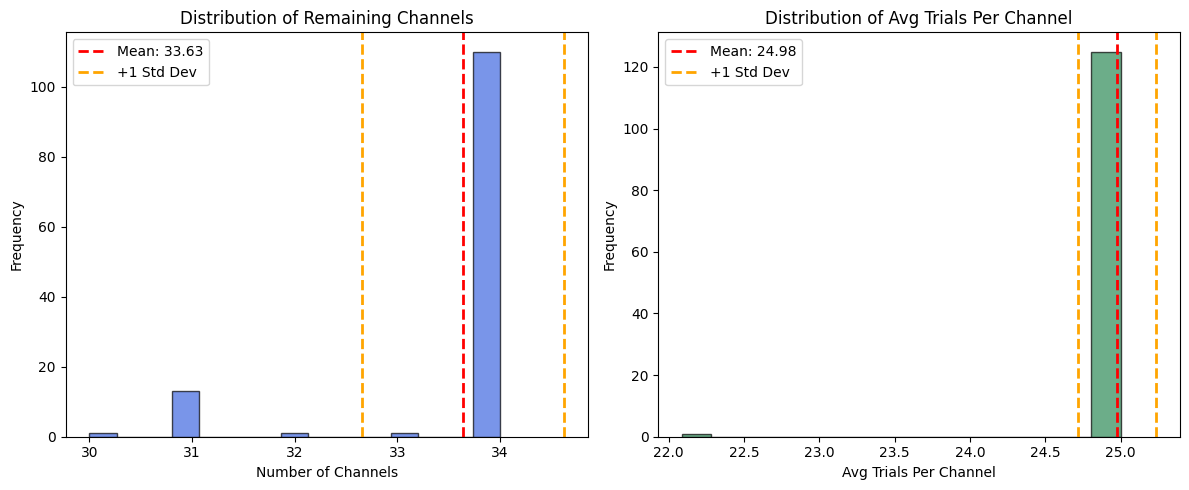

In [205]:
# Plot histograms
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Histogram for remaining channels
axs[0].hist(remaining_channels_list, bins=15, color='royalblue', alpha=0.7, edgecolor='black')
axs[0].axvline(mean_remaining_channels, color='red', linestyle='dashed', linewidth=2, label=f"Mean: {mean_remaining_channels:.2f}")
axs[0].axvline(mean_remaining_channels + std_remaining_channels, color='orange', linestyle='dashed', linewidth=2, label=f"+1 Std Dev")
axs[0].axvline(mean_remaining_channels - std_remaining_channels, color='orange', linestyle='dashed', linewidth=2)
axs[0].set_title("Distribution of Remaining Channels")
axs[0].set_xlabel("Number of Channels")
axs[0].set_ylabel("Frequency")
axs[0].legend()

# Histogram for average trials per channel
axs[1].hist(avg_trials_per_channel_list, bins=15, color='seagreen', alpha=0.7, edgecolor='black')
axs[1].axvline(mean_avg_trials, color='red', linestyle='dashed', linewidth=2, label=f"Mean: {mean_avg_trials:.2f}")
axs[1].axvline(mean_avg_trials + std_avg_trials, color='orange', linestyle='dashed', linewidth=2, label=f"+1 Std Dev")
axs[1].axvline(mean_avg_trials - std_avg_trials, color='orange', linestyle='dashed', linewidth=2)
axs[1].set_title("Distribution of Avg Trials Per Channel")
axs[1].set_xlabel("Avg Trials Per Channel")
axs[1].set_ylabel("Frequency")
axs[1].legend()

plt.tight_layout()
plt.show()